# Задание 4.4

Предположим, что «симметричную» монету бросают до тех пор, пока она не выпадет дважды одной и той же стороной подряд. Построить вероятностную модель, т.е. $(\Omega,\mathbb P(\cdot))$, и найдите вероятность того, что потребуется чётное число бросаний.

**Ответ:** $\dfrac23$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Пространство элементарных исходов.** Опыт останавливается, как только два последних броска совпали. Значит, до этого стороны **чередовались**. Для каждого числа бросаний $n\ge2$ есть ровно два исхода (в зависимости от первого броска):

$$
\Omega=\{\omega_n^{\text{Г}},\ \omega_n^{\text{Р}}:\ n=2,3,\dots\},\qquad
\omega_n^{\text{Г}}=\underbrace{\text{Г Р Г Р}\dots}_{n-1\ \text{чередуются}}\ \text{+ повтор последнего},
$$

например: $\omega_2^{\text{Г}}=\text{ГГ}$, $\omega_3^{\text{Г}}=\text{ГРР}$, $\omega_4^{\text{Г}}=\text{ГРГГ}$, $\omega_2^{\text{Р}}=\text{РР}$, $\omega_3^{\text{Р}}=\text{РГГ}$, …

**Вероятности.** Броски независимы, каждая конкретная последовательность длины $n$ имеет вероятность $2^{-n}$:

$$
\mathbb P(\omega_n^{\text{Г}})=\mathbb P(\omega_n^{\text{Р}})=\frac{1}{2^n},\qquad
\mathbb P(\tau=n)=\frac{2}{2^n}=\frac{1}{2^{n-1}},\quad n\ge2,
$$

где $\tau$ — число бросаний. Проверка нормировки: $\sum_{n\ge2}2^{1-n}=1$.

(Иначе: каждый бросок, начиная со второго, совпадает с предыдущим с вероятностью $\frac12$ независимо от прошлого, поэтому $\tau-1$ — геометрическая величина с $p=\frac12$.)

**Чётное число бросаний:**

$$
\mathbb P(\tau\ \text{чётно})=\sum_{k=1}^{\infty}\mathbb P(\tau=2k)=\sum_{k=1}^{\infty}\frac{1}{2^{2k-1}}=2\cdot\frac{1/4}{1-1/4}=\frac23\approx0{,}6667 .
$$

**Статистическая проверка:** моделируем броски, находим первое $n$ с совпадением двух подряд и строим частоту чётных $\tau$.

n = 2:     ГГ,     РР;  P(τ = n) = 2/2^2 = 1/2
n = 3:    ГРР,    РГГ;  P(τ = n) = 2/2^3 = 1/4
n = 4:   ГРГГ,   РГРР;  P(τ = n) = 2/2^4 = 1/8
n = 5:  ГРГРР,  РГРГГ;  P(τ = n) = 2/2^5 = 1/16
Частичная сумма ряда до n = 60: 0.666666666667;  P = 2/3


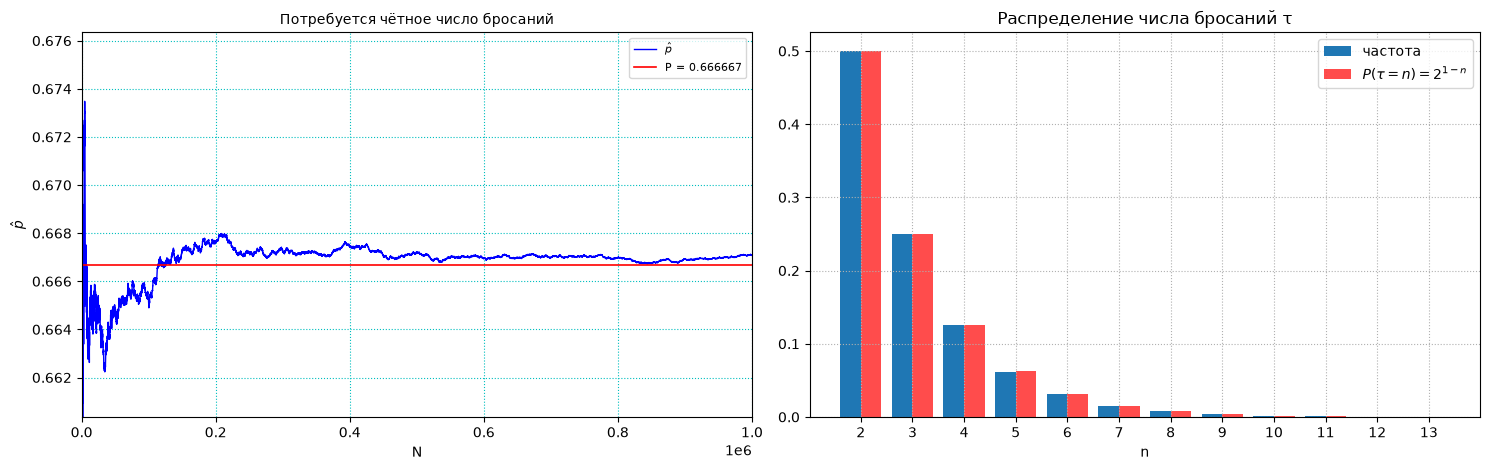

p̂ = 0.667075 при N = 1000000;  P = 2/3 = 0.666667


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Модель (Ω, P): несколько первых исходов ----------
for n in range(2, 6):
    alt_G = "".join("ГР"[i % 2] for i in range(n - 1))          # чередование, начиная с Г
    alt_R = "".join("РГ"[i % 2] for i in range(n - 1))          # чередование, начиная с Р
    print(f"n = {n}: {alt_G + alt_G[-1]:>6}, {alt_R + alt_R[-1]:>6};  P(τ = n) = 2/2^{n} = {Fraction(2, 2**n)}")

P_even = Fraction(2, 3)                                         # сумма ряда sum 1/2^(2k-1)
print(f"Частичная сумма ряда до n = 60: {float(sum(Fraction(1, 2**(2*k - 1)) for k in range(1, 31))):.12f};  P = {P_even}")

# ---------- Моделирование ----------
N, K = 1_000_000, 64
t = rng.integers(0, 2, size=(N, K), dtype=np.int8)              # 1 — герб, 0 — решка
same = t[:, 1:] == t[:, :-1]                                    # совпадение броска с предыдущим
tau = same.argmax(axis=1) + 2                                   # число бросаний до первой пары
hits = tau % 2 == 0                                             # событие «чётное число бросаний»

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ph = plot_freq(axes[0], hits, float(P_even), "Потребуется чётное число бросаний")
n = np.arange(2, 14)
axes[1].bar(n - 0.2, [(tau == j).mean() for j in n], width=0.4, label="частота")
axes[1].bar(n + 0.2, 2.0**(1 - n), width=0.4, color="red", alpha=0.7, label=r"$P(\tau=n)=2^{1-n}$")
axes[1].set_xticks(n); axes[1].set_xlabel("n"); axes[1].set_title("Распределение числа бросаний τ")
axes[1].grid(ls=":"); axes[1].legend()
fig.tight_layout()
plt.show()

print(f"p̂ = {ph:.6f} при N = {N};  P = 2/3 = {2/3:.6f}")